# 02 · Modelling

Two models are compared, both trained on log price and returning dollars (code in `freight/models.py`):

* **Baseline: plain linear regression** on the cleaned feature table as it is: distance, equipment, weight, market index, cities and their coordinates, and the calendar features.
* **Final model: a regularised linear model** whose inputs follow the EDA:
  * smooth curves for distance (fixed charge plus per-mile rate) and weight (S-shaped);
  * a straight-line market index effect and upward drift;
  * a quarter-end ramp sized separately for each equipment type;
  * weekday, equipment, pickup and delivery city;
  * lane (city-pair) effects, shrunk strongly because each lane has only ~10 loads.

Sections 1–3 use the four walk-forward folds inside January–August (`freight/validation.py`): each fold trains on the months up to a cut-off and predicts the following two months, exactly as the final model will predict November–December. All modelling choices were made on these folds. Section 4 then scores both models once on the September–October test period, which played no part in building them. Corrupted prices are removed from training and from scoring throughout.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "train_test.csv").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, MultipleLocator

from freight import style as S
from freight.cleaning import LabelScreen
from freight.data import TARGET, load_labelled
from freight.evaluate import MODELS, predict_splits, summarise
from freight.features import QUARTER_END_SHAPE, QUARTER_END_WINDOW, FeatureBuilder
from freight.models import EQUIPMENT, LANE_SHRINK, RAMPS, final_model
from freight.validation import FOLDS, TEST, development

S.apply_style()
pd.set_option("display.width", 160)
BASE, FINAL = MODELS
COLORS = {BASE: S.NEUTRAL, FINAL: S.BLUE}
SHORT = {BASE: "Baseline", FINAL: "Final model"}

df = load_labelled()
predictions = predict_splits(df, FOLDS)
predictions["pct_error"] = predictions.predicted / predictions.actual - 1
print(f"{predictions.groupby('model').size().iloc[0]:,} evaluated loads per model across the four folds")

38,280 evaluated loads per model across the four folds


## 1 · Walk-forward results

In [2]:
by_fold = summarise(predictions)
average = by_fold.groupby(level="model", sort=False)[["MAPE", "MAE ($)", "bias"]].mean()
with pd.option_context("display.float_format", "{:.4f}".format):
    print(by_fold[["MAPE", "MAE ($)", "bias"]].unstack("model").swaplevel(axis=1).sort_index(axis=1, level=0))
    print("\nAverage over the four folds:\n", average)

# Load-by-load: are the final model's gains real or noise?
wide = predictions.assign(ape=predictions.pct_error.abs()).pivot_table(index=["split", "row"], columns="model", values="ape")
gain = wide[BASE] - wide[FINAL]
print(f"\nFinal model is more accurate on {(gain > 0).mean():.0%} of individual loads; average gain "
      f"{gain.mean() * 100:.2f} percentage points (standard error {gain.std() / np.sqrt(len(gain)) * 100:.3f})")
print("Folds where the final model wins:", int((by_fold.MAPE.unstack('model')[FINAL] < by_fold.MAPE.unstack('model')[BASE]).sum()), "of 4")

model  Baseline: linear regression                Final model               
                           MAE ($)   MAPE    bias     MAE ($)   MAPE    bias
split                                                                       
Fold 1                     47.0406 0.0190 -0.0137     33.9749 0.0137 -0.0053
Fold 2                     39.1625 0.0160 -0.0043     33.7722 0.0134 -0.0057
Fold 3                     38.7448 0.0161  0.0008     31.2650 0.0127 -0.0028
Fold 4                     42.6417 0.0182  0.0111     34.8028 0.0148  0.0088

Average over the four folds:
                               MAPE  MAE ($)    bias
model                                              
Baseline: linear regression 0.0173  41.8974 -0.0015
Final model                 0.0137  33.4537 -0.0013



Final model is more accurate on 63% of individual loads; average gain 0.37 percentage points (standard error 0.005)
Folds where the final model wins: 4 of 4


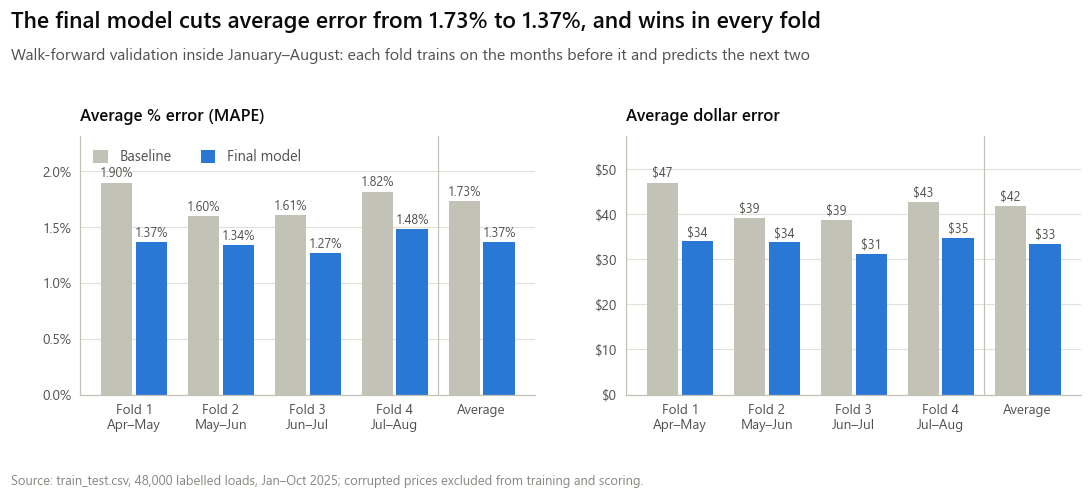

In [3]:
folds = [f.name for f in FOLDS]
fold_labels = [f"{f.name}\n{f.eval_start:%b}–{f.eval_end:%b}" for f in FOLDS] + ["Average"]
fig = plt.figure(figsize=(10, 4.6))
gs = fig.add_gridspec(1, 2, left=0.075, right=0.985, top=S.top(fig, 1.3), bottom=S.bottom(fig, 0.95), wspace=0.2)
for i, (metric, title, fmt) in enumerate([("MAPE", "Average % error (MAPE)", lambda v: S.pct(v, 2)),
                                          ("MAE ($)", "Average dollar error", lambda v: f"${v:.0f}")]):
    ax = fig.add_subplot(gs[i])
    x = np.arange(len(fold_labels))
    bw = 0.36
    for j, name in enumerate(MODELS):
        vals = list(by_fold[metric].unstack("model")[name].reindex(folds)) + [average.loc[name, metric]]
        xs = x + (j - 0.5) * (bw + 0.04)
        ax.bar(xs, vals, width=bw, color=COLORS[name])
        for xv, v in zip(xs, vals):
            ax.text(xv, v * 1.015, fmt(v), ha="center", va="bottom", fontsize=8.3, color=S.INK_2)
    ax.axvline(len(folds) - 0.5, color=S.AXIS, lw=0.8)
    ax.set_xticks(x, fold_labels)
    ax.tick_params(axis="x", labelsize=8.8)
    top = by_fold[metric].max() * 1.22
    ax.set_ylim(0, top)
    if metric == "MAPE":
        ax.yaxis.set_major_locator(MultipleLocator(0.005))
        S.pct_axis(ax, "y", decimals=1)
    else:
        S.dollar_axis(ax)
    S.panel_title(ax, title)
fig.axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORS[n], label=SHORT[n]) for n in MODELS],
                   loc="upper left", ncol=2, handlelength=1, handleheight=1)
S.headline(fig, f"The final model cuts average error from {S.pct(average.loc[BASE, 'MAPE'], 2)} to "
                f"{S.pct(average.loc[FINAL, 'MAPE'], 2)}, and wins in every fold",
           "Walk-forward validation inside January–August: each fold trains on the months before it and predicts "
           "the next two")
S.footnote(fig, S.SOURCE_NOTE + "; corrupted prices excluded from training and scoring.")
S.save(fig, "01_fold_results", subdir="model")
plt.show()

**What this means.** The final model is more accurate than the baseline in every fold, cutting the average error by about a fifth (roughly $8 per load), and it wins on most individual loads, so the gain is not luck. Its error sits close to the ~2% price noise found in the EDA, which no model can predict.

## 2 · Where the gains come from

In [4]:
predictions["distance_band"] = pd.qcut(predictions.distance, 5)
predictions["week_ahead"] = ((predictions.date - predictions.groupby("split").date.transform("min")).dt.days // 7 + 1).clip(upper=9)
by_equipment = summarise(predictions, by=("model", "equipment")).MAPE.unstack("model").reindex(EQUIPMENT)
by_distance = summarise(predictions, by=("model", "distance_band")).MAPE.unstack("model").sort_index()
by_week = summarise(predictions, by=("model", "week_ahead")).MAPE.unstack("model").sort_index()
band_labels = [f"{iv.left:,.0f}–\n{iv.right:,.0f}" for iv in by_distance.index]
band_labels[0] = band_labels[0].replace(f"{by_distance.index[0].left:,.0f}", f"{predictions.distance.min():,.0f}")
print(by_equipment.round(4)); print(by_distance.round(4)); print(by_week.round(4))

model      Baseline: linear regression  Final model
equipment                                          
Dry Van                         0.0170       0.0137
Reefer                          0.0172       0.0137
Flatbed                         0.0185       0.0134
model              Baseline: linear regression  Final model
distance_band                                              
(69.999, 475.7]                         0.0171       0.0129
(475.7, 789.6]                          0.0168       0.0133
(789.6, 1151.3]                         0.0171       0.0134
(1151.3, 1836.82]                       0.0176       0.0141
(1836.82, 3362.3]                       0.0179       0.0145
model       Baseline: linear regression  Final model
week_ahead                                          
1                                0.0155       0.0128
2                                0.0152       0.0125
3                                0.0166       0.0129
4                                0.0177       0.0136
5 

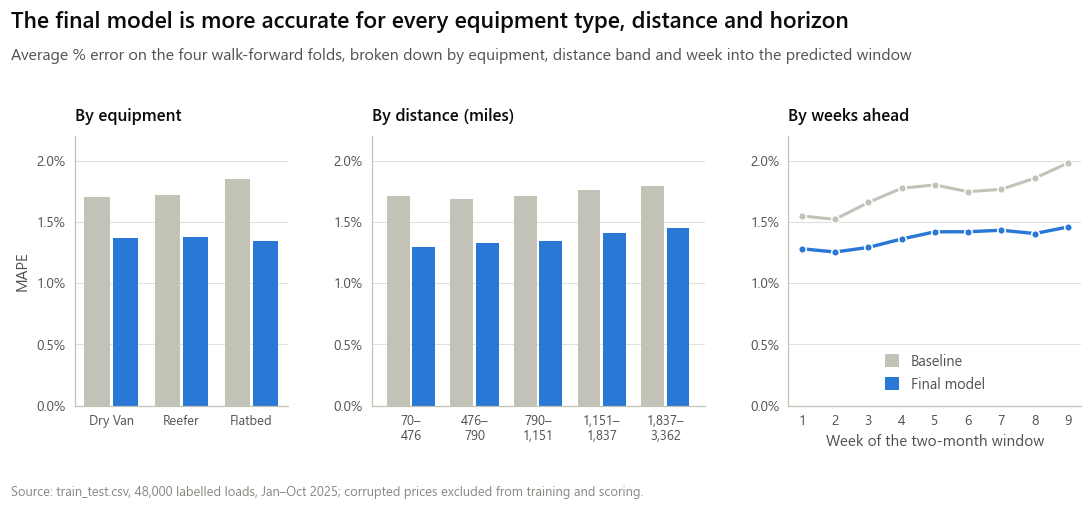

In [5]:
fig = plt.figure(figsize=(10, 4.7))
gs = fig.add_gridspec(1, 3, width_ratios=[0.8, 1.25, 1.1], left=0.07, right=0.985, top=S.top(fig, 1.3),
                      bottom=S.bottom(fig, 0.95), wspace=0.3)
for k, (table, labels, title) in enumerate([(by_equipment, EQUIPMENT, "By equipment"),
                                            (by_distance, band_labels, "By distance (miles)")]):
    ax = fig.add_subplot(gs[k])
    x = np.arange(len(table))
    bw = 0.36
    for j, name in enumerate(MODELS):
        ax.bar(x + (j - 0.5) * (bw + 0.04), table[name].values, width=bw, color=COLORS[name])
    ax.set_xticks(x, labels)
    ax.tick_params(axis="x", labelsize=8.5)
    ax.set_ylim(0, 0.022)
    ax.yaxis.set_major_locator(MultipleLocator(0.005))
    S.pct_axis(ax, "y", decimals=1)
    S.panel_title(ax, title)
fig.axes[0].set_ylabel("MAPE")
ax = fig.add_subplot(gs[2])
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORS[n], label=SHORT[n]) for n in MODELS],
          loc="lower center", handlelength=1, handleheight=1)
for name in MODELS:
    ax.plot(by_week.index, by_week[name], color=COLORS[name], lw=2.2 if name == FINAL else 2, marker="o", ms=5,
            mec=S.SURFACE, mew=1)
ax.set_xticks(by_week.index)
ax.set_ylim(0, 0.022)
ax.yaxis.set_major_locator(MultipleLocator(0.005))
S.pct_axis(ax, "y", decimals=1)
ax.set_xlabel("Week of the two-month window")
S.panel_title(ax, "By weeks ahead")
S.headline(fig, "The final model is more accurate for every equipment type, distance and horizon",
           "Average % error on the four walk-forward folds, broken down by equipment, distance band and week "
           "into the predicted window")
S.footnote(fig, S.SOURCE_NOTE + "; corrupted prices excluded from training and scoring.")
S.save(fig, "02_error_breakdown", subdir="model")
plt.show()

**What this means.** The gains are broad rather than concentrated in one corner: every equipment type, every distance band and every week of the two-month window improves. Flatbeds gain most, because their quarter-end surge is the largest and the final model sizes it separately. The gap also widens with distance into the future: the baseline's error climbs from about 1.5% in the first week to 2.0% by the ninth, while the final model stays near 1.3–1.5%. That matters because Spotter's loads lie one to two months beyond the training data.

## 3 · What the final model learned

To read the model, it is fitted once on all development data (January–August, corrupted prices removed). Its effects are multiplicative, so each is shown as a percentage change in price.

In [6]:
dev = development(df)
dev = dev[~LabelScreen().fit(dev).flag(dev)]
builder = FeatureBuilder().fit(dev)
X_dev, y_dev = builder.transform(dev), dev[TARGET]
model = final_model().fit(X_dev, y_dev)
pipe = model.regressor_
coef = pd.Series(pipe[-1].coef_, index=pipe[1].get_feature_names_out())

def lift(c):
    return np.exp(c) - 1

effects = {
    "Reefer vs Dry Van": lift(coef["categories__equipment_Reefer"]),
    "Flatbed vs Dry Van": lift(coef["categories__equipment_Flatbed"]),
    "Market index +0.1": lift(0.1 * coef["straight_line__market_index"]),
    "Upward drift per month": lift(30 / 100 * coef["straight_line__trend"]),
    **{f"Quarter-end surge, last day: {e}": lift(coef[f"straight_line__{r}"]) for e, r in zip(EQUIPMENT, RAMPS)},
}
weekday = pd.Series({0: 0.0, **{int(k.split("_")[-1]): v for k, v in coef.filter(like="weekday_").items()}}).sort_index()
pick = coef.filter(like="cities__pickup_")
drop = coef.filter(like="cities__delivery_")
lanes = coef.filter(like="lanes__") * LANE_SHRINK
print(pd.Series(effects).map(lambda v: f"{v:+.2%}").to_string())
print(f"Weekday effects vs Monday: {', '.join(f'{d}: {lift(v):+.2%}' for d, v in zip(['Mon','Tue','Wed','Thu','Fri','Sat','Sun'], weekday))}")
print(f"City effects (pickup) range {lift(pick.min() - pick.mean()):+.1%} to {lift(pick.max() - pick.mean()):+.1%}; "
      f"lane effects spread ±{lanes.std():.2%}")

Reefer vs Dry Van                       +12.49%
Flatbed vs Dry Van                       +7.53%
Market index +0.1                        +1.56%
Upward drift per month                   +0.52%
Quarter-end surge, last day: Dry Van     +2.59%
Quarter-end surge, last day: Reefer      +5.45%
Quarter-end surge, last day: Flatbed     +8.58%
Weekday effects vs Monday: Mon: +0.00%, Tue: -0.27%, Wed: -0.52%, Thu: -0.62%, Fri: -0.48%, Sat: -0.18%, Sun: +0.04%
City effects (pickup) range -3.7% to +3.2%; lane effects spread ±0.82%


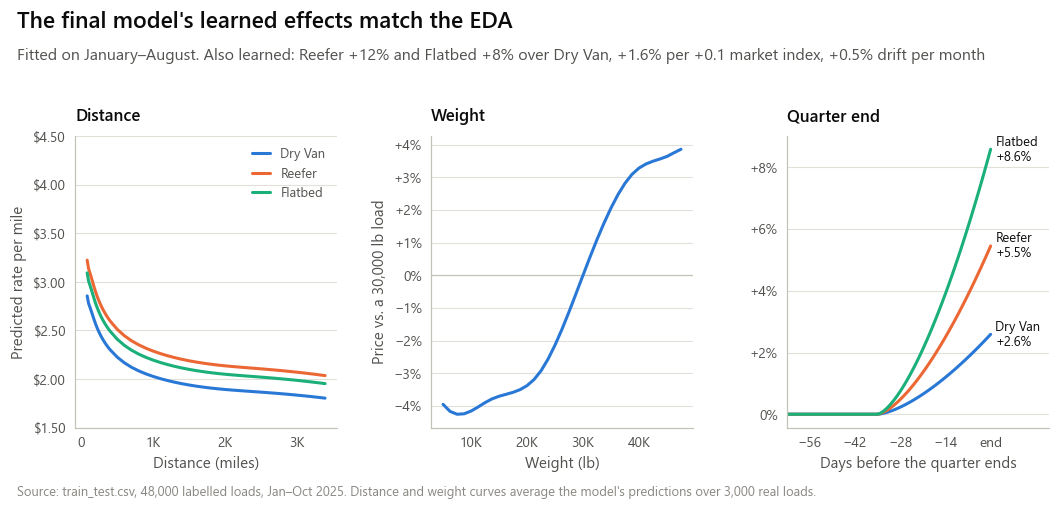

In [7]:
rng = np.random.default_rng(0)
sample = X_dev.iloc[rng.choice(len(X_dev), 3000, replace=False)]

def average_price(**changes):
    X = sample.copy()
    for col, value in changes.items():
        X[col] = pd.Categorical([value] * len(X), categories=X[col].cat.categories) if col == "equipment" else value
    return model.predict(X).mean()

miles = np.r_[np.arange(80, 400, 20), np.arange(400, 3401, 100)]
per_mile = {e: [average_price(distance=d, log_distance=np.log(d), equipment=e) / d for d in miles] for e in EQUIPMENT}
pounds = np.arange(5000, 47501, 1250)
ref = average_price(weight=30000)
weight_effect = [average_price(weight=w, weight_capped=int(w == 47500)) / ref - 1 for w in pounds]

fig = plt.figure(figsize=(10, 4.7))
gs = fig.add_gridspec(1, 3, left=0.065, right=0.95, top=S.top(fig, 1.3), bottom=S.bottom(fig, 0.75), wspace=0.36)
ax = fig.add_subplot(gs[0])
for e in EQUIPMENT:
    ax.plot(miles, per_mile[e], color=S.EQUIPMENT_COLORS[e], lw=2, label=e)
ax.set_ylim(1.5, 4.5)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:.2f}"))
S.thousands_axis(ax, "x")
ax.set_xlabel("Distance (miles)")
ax.set_ylabel("Predicted rate per mile")
ax.legend(loc="upper right", fontsize=8.5)
S.panel_title(ax, "Distance")

ax = fig.add_subplot(gs[1])
ax.axhline(0, color=S.AXIS, lw=0.8)
ax.plot(pounds, weight_effect, color=S.BLUE, lw=2)
S.thousands_axis(ax, "x")
S.pct_axis(ax, "y", signed=True)
ax.set_xlabel("Weight (lb)")
ax.set_ylabel("Price vs. a 30,000 lb load")
S.panel_title(ax, "Weight")

ax = fig.add_subplot(gs[2])
days = np.arange(0, 64)
ramp = ((QUARTER_END_WINDOW - days) / QUARTER_END_WINDOW).clip(0, 1) ** QUARTER_END_SHAPE
for e, r in zip(EQUIPMENT, RAMPS):
    size = effects[f"Quarter-end surge, last day: {e}"]
    ax.plot(-days, lift(coef[f"straight_line__{r}"] * ramp), color=S.EQUIPMENT_COLORS[e], lw=2)
    ax.text(1.5, size, f"{e}\n{S.pct(size, 1, True)}", va="center", fontsize=8.5, color=S.INK, linespacing=1.2)
ax.set_xlim(-63, 18)
ax.set_xticks([-56, -42, -28, -14, 0])
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: "end" if v == 0 else f"{v:.0f}".replace("-", "−")))
ax.yaxis.set_major_locator(MultipleLocator(0.02))
S.pct_axis(ax, "y", signed=True)
ax.set_xlabel("Days before the quarter ends")
S.panel_title(ax, "Quarter end")

S.headline(fig, "The final model's learned effects match the EDA",
           f"Fitted on January–August. Also learned: Reefer {S.pct(effects['Reefer vs Dry Van'], 0, True)} and Flatbed "
           f"{S.pct(effects['Flatbed vs Dry Van'], 0, True)} over Dry Van, {S.pct(effects['Market index +0.1'], 1, True)} "
           f"per +0.1 market index, {S.pct(effects['Upward drift per month'], 1, True)} drift per month")
S.footnote(fig, S.SOURCE_NOTE + ". Distance and weight curves average the model's predictions over 3,000 real loads.")
S.save(fig, "03_what_the_model_learned", subdir="model")
plt.show()

**What this means.** The model has learned the same structure the EDA found, which is what makes it trustworthy beyond the months it was trained on:
* a fixed charge plus a per-mile rate, so short hauls cost more per mile, with Reefer and Flatbed a steady percentage above Dry Van;
* an S-shaped weight effect;
* a market-index effect and a steady upward drift, both of which carry forward into later months;
* a quarter-end surge that is several times larger for flatbeds than for dry vans.

Every piece is an effect a pricing analyst can read and sanity-check, which is a practical advantage over a black-box model.

## 4 · Test period: September–October

The two months held back from the start. Both models are trained on January–August and scored once on September–October; nothing was changed after seeing these numbers. September ends a quarter, as December does, so the test includes a quarter-end surge.

In [8]:
test_predictions = predict_splits(df, (TEST,))
test_predictions["month"] = test_predictions.date.dt.strftime("%B")
test_table = summarise(test_predictions, by=("model",))
test_by_month = summarise(test_predictions, by=("model", "month"))
with pd.option_context("display.float_format", "{:.4f}".format):
    print(test_table)
    print(test_by_month)
test_wide = test_predictions.assign(ape=(test_predictions.predicted / test_predictions.actual - 1).abs()) \
    .pivot_table(index="row", columns="model", values="ape")
test_gain = test_wide[BASE] - test_wide[FINAL]
print(f"\nFinal model more accurate on {(test_gain > 0).mean():.0%} of test loads; average gain "
      f"{test_gain.mean() * 100:.2f} percentage points (standard error {test_gain.std() / np.sqrt(len(test_gain)) * 100:.3f})")

                              MAPE  MAE ($)    bias     loads
model                                                        
Baseline: linear regression 0.0170  39.2986 -0.0048 9379.0000
Final model                 0.0141  32.6799 -0.0076 9379.0000
                                        MAPE  MAE ($)    bias     loads
model                       month                                      
Baseline: linear regression September 0.0170  39.7970  0.0000 4606.0000
                            October   0.0170  38.8177 -0.0095 4773.0000
Final model                 September 0.0123  28.6124 -0.0029 4606.0000
                            October   0.0159  36.6051 -0.0121 4773.0000

Final model more accurate on 59% of test loads; average gain 0.29 percentage points (standard error 0.012)


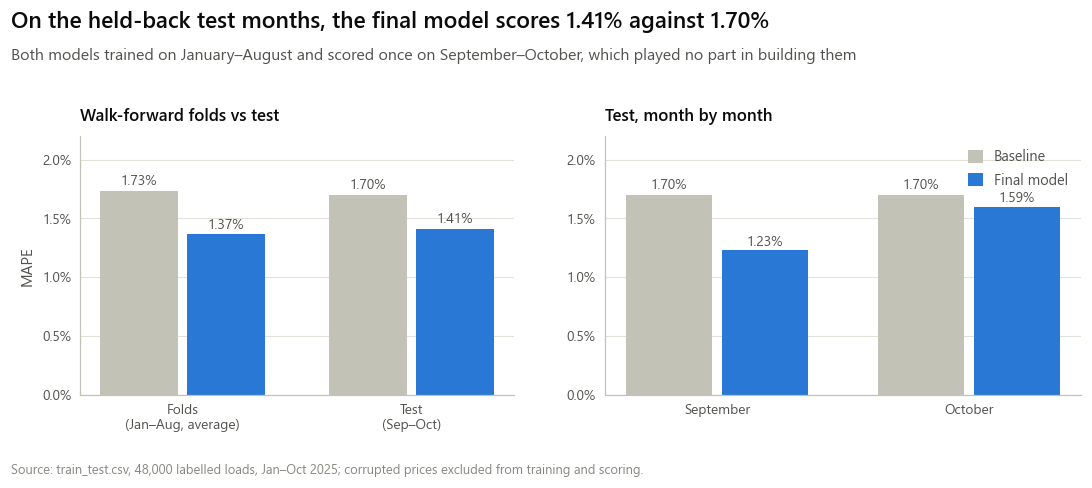

In [9]:
fig = plt.figure(figsize=(10, 4.5))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.1], left=0.075, right=0.985, top=S.top(fig, 1.3),
                      bottom=S.bottom(fig, 0.85), wspace=0.2)
months = list(dict.fromkeys(test_predictions.sort_values("date").month))
panels = [
    ("Walk-forward folds vs test", ["Folds\n(Jan–Aug, average)", "Test\n(Sep–Oct)"],
     {n: [average.loc[n, "MAPE"], test_table.loc[n, "MAPE"]] for n in MODELS}),
    ("Test, month by month", months,
     {n: [test_by_month.loc[(n, m), "MAPE"] for m in months] for n in MODELS}),
]
for k, (title, labels, values) in enumerate(panels):
    ax = fig.add_subplot(gs[k])
    x = np.arange(len(labels))
    bw = 0.34
    for j, name in enumerate(MODELS):
        xs = x + (j - 0.5) * (bw + 0.04)
        ax.bar(xs, values[name], width=bw, color=COLORS[name])
        for xv, v in zip(xs, values[name]):
            ax.text(xv, v * 1.015, S.pct(v, 2), ha="center", va="bottom", fontsize=9, color=S.INK_2)
    ax.set_xticks(x, labels)
    ax.set_ylim(0, 0.022)
    ax.yaxis.set_major_locator(MultipleLocator(0.005))
    S.pct_axis(ax, "y", decimals=1)
    S.panel_title(ax, title)
fig.axes[0].set_ylabel("MAPE")
fig.axes[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORS[n], label=SHORT[n]) for n in MODELS],
                   loc="upper right", handlelength=1, handleheight=1)
winner, other = (FINAL, BASE) if test_table.loc[FINAL, "MAPE"] < test_table.loc[BASE, "MAPE"] else (BASE, FINAL)
S.headline(fig, f"On the held-back test months, the {SHORT[winner].lower()} scores {S.pct(test_table.loc[winner, 'MAPE'], 2)} "
                f"against {S.pct(test_table.loc[other, 'MAPE'], 2)}",
           "Both models trained on January–August and scored once on September–October, which played no part in "
           "building them")
S.footnote(fig, S.SOURCE_NOTE + "; corrupted prices excluded from training and scoring.")
S.save(fig, "04_test_results", subdir="model")
plt.show()

**What this means.** On two months it had never seen, the final model's error is **1.41% against the baseline's 1.70%** (about $33 against $39 per load), in line with the walk-forward estimates (1.37% against 1.73%), so those estimates were not flattering. September, which ends a quarter as December does, is the final model's best month at 1.23%: the equipment-specific quarter-end ramp holds up on new data. October is harder (1.59%): both models under-price it by about 1% on average, a sign that prices stepped up after the September quarter end by more than the steady drift implies. The model that predicts November–December is trained on all ten months, October included.